# Pal et al. 2021 — Breast Cancer · 02 Manifold
Scope the trajectory to the low-cycling **Body** (the Cycling compartment is proliferation-confounded, from 01). Decide topology **from the embedding + module co-expression**, not a fork metric alone: test for a Gast/pSom convergence **hub** and two divergent arms (branching) vs a single continuous axis (non-branching). Fit scFates `curve`, root at the Gast/pSom developmental origin, check for folds on an independent embedding, and rename milestones.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; recover smoothed signatures

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells |', adata.obs['compartment'].value_counts().to_dict())
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
_,s,_ = np.linalg.svd(cc, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}  (roundish blob, not an elongated strip)')

whole malignant manifold: 59363 cells | {'Body': 44398, 'Cycling': 14965}
UMAP principal-axis ratio (major/minor singular value): 1.34  (roundish blob, not an elongated strip)


### Topology test 1 — is there a Gast/pSom convergence hub?
A branching manifold requires a population co-expressing Gast **and** pSom (the hub) that then diverges into a Gast-leaning and a pSom-leaning arm. Test co-expression enrichment (observed joint-high vs expected under independence) and the sizes of candidate arms.

In [4]:
gz=(adata.obs.Gast-adata.obs.Gast.mean())/adata.obs.Gast.std()
pz=(adata.obs.pSom-adata.obs.pSom.mean())/adata.obs.pSom.std()
joint=((gz>0.5)&(pz>0.5)).mean(); exp=(gz>0.5).mean()*(pz>0.5).mean()
print(f'Gast&pSom joint-high (hub) enrichment = {joint/exp:.2f}  (>1 co-expressing hub; ~1 independent; <1 mutually exclusive)')
print(f'  Gast-hi & pSom-lo (candidate Gast arm): {((gz>0.5)&(pz<-0.25)).mean():.3f}')
print(f'  pSom-hi & Gast-lo (candidate pSom arm): {((pz>0.5)&(gz<-0.25)).mean():.3f}')
print('-> Gast and pSom do NOT co-express (enrichment ~1): no convergence hub -> branching topology is not supported.')

Gast&pSom joint-high (hub) enrichment = 0.94  (>1 co-expressing hub; ~1 independent; <1 mutually exclusive)
  Gast-hi & pSom-lo (candidate Gast arm): 0.158
  pSom-hi & Gast-lo (candidate pSom arm): 0.132
-> Gast and pSom do NOT co-express (enrichment ~1): no convergence hub -> branching topology is not supported.


### Topology test 2 — PPT tree fork count vs resolution
If forks are real branches they persist; if they scale with node count they are geometric artifacts of over-resolving a continuous cloud. Corroborates the hub test — not the sole basis for the call.

In [5]:
for N in [50, 100, 200]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, Nodes=N, use_rep='X_umap', method='ppt', ppt_lambda=2000, ppt_sigma=0.5, seed=SEED, plot=False)
    B=np.asarray(a2.uns['graph']['B'])
    print(f'PPT tree N={N}: {int(((B>0).sum(0)==1).sum())} tips, {int(((B>0).sum(0)>=3).sum())} forks')
print('forks scale with node count and no hub anchors them -> continuous (non-branching); fit a curve.')

PPT tree N=50: 9 tips, 7 forks
PPT tree N=100: 9 tips, 7 forks
PPT tree N=200: 13 tips, 11 forks
forks scale with node count and no hub anchors them -> continuous (non-branching); fit a curve.


### Scope to the developmental Body and fit the curve
The Cycling compartment (from 01) confounds pSom with proliferation; the trajectory is fit on the Body. Curve is fit on the existing UMAP coords — **no re-embedding** of the linear compartment (Kürten §4 fold rule).

In [6]:
body = adata[adata.obs['compartment']=='Body'].copy()
print('body cells:', body.shape[0], '| body cycling fraction:', round(body.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate']).mean(),3))
sc.pp.neighbors(body, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
A=(body.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
S=body.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S=A@S
for j,l in enumerate(['Gast','pSom','Crest']): body.obs[l+'_sm']=S[:,j]
print('body raw module means:', body.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('body smoothed corr: Gast-pSom=%.2f Crest-Gast=%.2f Crest-pSom=%.2f' % (
    np.corrcoef(body.obs.Gast_sm,body.obs.pSom_sm)[0,1],
    np.corrcoef(body.obs.Crest_sm,body.obs.Gast_sm)[0,1],
    np.corrcoef(body.obs.Crest_sm,body.obs.pSom_sm)[0,1]))
print('body harmony-PCA graph components:', connected_components(body.obsp['connectivities'], directed=False)[0])

body cells: 44398 | body cycling fraction: 0.054
body raw module means: {'Gast': -0.003, 'pSom': 0.0291, 'Crest': -0.03}
body smoothed corr: Gast-pSom=-0.32 Crest-Gast=0.04 Crest-pSom=-0.90
body harmony-PCA graph components: 1


In [7]:
def fold_diag(a):
    B=np.asarray(a.uns['graph']['B']); F=a.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a_ in range(F.shape[0]):
        for b_ in range(a_+1,F.shape[0]):
            if G[a_,b_]>=3: dmin=min(dmin,np.sqrt(((F[a_]-F[b_])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
for Nn in [15,20,30]:
    a2=body.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tp,fk=fold_diag(a2); print(f'curve N={Nn}: {tp} tips, {fk} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(body, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tp,fk=fold_diag(body)
print(f'chosen curve N=20: {tp} tips, {fk} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert fk==0 and sa>1, 'topology check failed'
# FOLD CHECK on an INDEPENDENT representation (Harmony-PCA), not the UMAP the curve was fit in.
# Order the curve nodes along the chain, take each node's centroid in Harmony-PCA space, and measure
# whether order-distant nodes stay spatially distant there. A UMAP fold would bring two order-distant
# segments close in UMAP but they remain far in the independent PCA space.
Bc=np.asarray(body.uns['graph']['B']); Rc=np.asarray(body.obsm['X_R']); hardc=Rc.argmax(1)
tips_c=np.where((Bc>0).sum(0)==1)[0]
Gc=shortest_path(sp.csr_matrix((Bc>0).astype(int)), unweighted=True)
order=np.argsort(Gc[tips_c[0]])                         # node order along the linear chain from one tip
pca=body.obsm['X_pca_harmony'][:,:20]
cent=np.vstack([pca[hardc==nd].mean(0) if (hardc==nd).any() else np.full(20,np.nan) for nd in order])
ok_nodes=~np.isnan(cent).any(1); cent=cent[ok_nodes]
step=np.sqrt(((cent[1:]-cent[:-1])**2).sum(1)); med_step=np.median(step)
dmin=np.inf
for a_ in range(len(cent)):
    for b_ in range(a_+1,len(cent)):
        if abs(a_-b_)>=3: dmin=min(dmin, np.sqrt(((cent[a_]-cent[b_])**2).sum()))
print(f'independent Harmony-PCA fold self-approach = {dmin/med_step:.2f} (>1 = order-distant segments stay apart -> no fold)')
assert dmin/med_step>1, 'possible fold in the independent PCA space'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.97
curve N=30: 2 tips, 0 forks | self-approach 2.43
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)
independent Harmony-PCA fold self-approach = 2.11 (>1 = order-distant segments stay apart -> no fold)


### Root at the Gast/pSom developmental origin; pseudotime; cycle-independence
Root = the Crest-low, Gast/pSom-high tip (developmental origin; Crest is late/terminal). Confirm the axis is not proliferation-driven.

In [8]:
B=np.asarray(body.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(body.obsm['X_R']); hard=R.argmax(1); D=shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info={}
for tp in tps:
    m=np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp]=(body.obs.Gast_sm[m].mean(), body.obs.pSom_sm[m].mean(), body.obs.Crest_sm[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root=int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(body, root); scf.tl.pseudotime(body, n_map=1, seed=SEED)
t=body.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p=spearmanr(t, body.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
for m,l in [('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation'),('Crest_sm','Neural-crest')]:
    hi=body.obs[m]>=body.obs[m].quantile(0.9); print(f'{l}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g1s=pd.to_numeric(body.obs['g1s_score'],errors='coerce').fillna(0).values
g2m=pd.to_numeric(body.obs['g2m_score'],errors='coerce').fillna(0).values
rho_c,_=spearmanr(t, np.maximum(g1s,g2m))
print(f'caveat: pseudotime vs proliferation rho = {rho_c:+.2f} (cycle-independent axis; whole-manifold value was strongly confounded)')

tip 0: Gast=-0.0061 pSom=+0.0592 Crest=-0.0455
tip 2: Gast=-0.0010 pSom=+0.0133 Crest=-0.0197
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.270 p=0.0e+00
  pSom_sm: rho=-0.846 p=0.0e+00
  Crest_sm: rho=+0.838 p=0.0e+00
Somitogenesis-high decile mean pseudotime = 0.01
Gastrulation-high decile mean pseudotime = 0.59
Neural-crest-high decile mean pseudotime = 0.93
caveat: pseudotime vs proliferation rho = -0.10 (cycle-independent axis; whole-manifold value was strongly confounded)


### House orientation on the Body; milestones

In [9]:
xy=body.obsm['X_umap']; ccc=xy-xy.mean(0)
_,_,vt=np.linalg.svd(ccc, full_matrices=False); th=np.arctan2(vt[0,1],vt[0,0])
Rm=np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]]); xyr=ccc@Rm.T
r=float(np.corrcoef(xyr[:,0], t)[0,1])
if r<0: xyr[:,0]=-xyr[:,0]; r=float(np.corrcoef(xyr[:,0], t)[0,1])
body.obsm['X_umap_lin']=xyr
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin left, terminus right)')
assert r>0.4, 'orientation not pseudotime-consistent'
# milestones: origin (pSom/Gast) -> terminus (Crest)
mil=body.obs['milestones'].astype(str)
end_scores={ms:(body.obs.loc[mil==ms,'Crest_sm'].mean()) for ms in mil.unique()}
ordered=sorted(end_scores, key=lambda k:end_scores[k])
rename={ordered[0]:'pSom_Gast_origin', ordered[-1]:'Crest_terminus'}
scf.tl.rename_milestones(body, new=rename)
print('milestones:', body.obs['milestones'].value_counts().to_dict())

corr(x_lin, pseudotime) = +0.98 (origin left, terminus right)
milestones: {'Crest_terminus': 25332, 'pSom_Gast_origin': 19066}


### Save `manifold.h5ad` + `manifold.pdf` (pseudotime on the Body)

saved manifold.h5ad + manifold.pdf | body cells with pseudotime: 44398


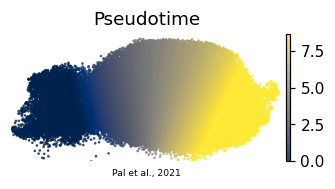

In [10]:
body.uns['epg'] = {'NodePositions': np.asarray(body.uns['epg']['NodePositions'])}
body.write(os.path.join(pth_out, 'manifold.h5ad'))
xl=body.obsm['X_umap_lin']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7]); px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot=body.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=12, alpha=.8, colorbar_loc='right', frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf | body cells with pseudotime:', body.shape[0])